In [403]:
from typing import List
import numpy as np
import scipy.sparse as sp

from Components.Controllers import LTI_LQRc_RHG

In [404]:
# Reload scripts when executed
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [405]:
A = np.array([[1, 1], [0, 1]])  # (2x2)

B0 = np.array([[1], [0]])
B1 = np.array([[0], [1]])
B2 = np.array([[1, 0], [1, 1]])
B_stack = [B0, B1, B2]
B_minus_v = [np.hstack([B1,B2]), np.hstack([B0,B2]), np.hstack([B0,B1])]

C = np.array([[1], [0]])

In [406]:
nx = 2
nu = 4
Nv = 3
nu_v = [1, 1, 2]
K=3

In [407]:
def form_B_tilde(A_powers: np.ndarray, B: np.ndarray) -> List[sp.lil_array]:
    B_tilde_v = []
    # Loop over agents
    for v, B_v in enumerate(B):
        # Compute all needed A^k B: shape (K, nx, nu)
        AkB = np.einsum('kij,jv->kiv', A_powers, B_v)
        # Lower triangular indices
        i_idx, j_idx = np.tril_indices(K)

        # Fetch the right A^k B for each block
        blocks = AkB[i_idx - j_idx]  # shape (num_blocks, nx, nu)

        # Step 4: Place blocks into final array
        result = sp.lil_array(((K+1) * nx, K * nu_v[v]))
        for idx, (i, j) in enumerate(zip(i_idx, j_idx)):
            result[(i+1)*nx:(i+2)*nx, j*nu_v[v]:(j+1)*nu_v[v]] = blocks[idx]
        B_tilde_v.append(result)
    
    return B_tilde_v

In [408]:
A_powers = np.array([np.linalg.matrix_power(A, k) for k in range(K + 1)])
A_powers

array([[[1, 0],
        [0, 1]],

       [[1, 1],
        [0, 1]],

       [[1, 2],
        [0, 1]],

       [[1, 3],
        [0, 1]]])

In [409]:
B_tilde = form_B_tilde(A_powers, B_stack)
[mat.toarray() for mat in B_tilde]

[array([[0., 0., 0.],
        [0., 0., 0.],
        [1., 0., 0.],
        [0., 0., 0.],
        [1., 1., 0.],
        [0., 0., 0.],
        [1., 1., 1.],
        [0., 0., 0.]]),
 array([[0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [1., 0., 0.],
        [1., 0., 0.],
        [1., 1., 0.],
        [2., 1., 0.],
        [1., 1., 1.]]),
 array([[0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0., 0.],
        [1., 1., 0., 0., 0., 0.],
        [2., 1., 1., 0., 0., 0.],
        [1., 1., 1., 1., 0., 0.],
        [3., 2., 2., 1., 1., 0.],
        [1., 1., 1., 1., 1., 1.]])]

In [410]:
Q_v = [np.array([[1,0], [0,i]]) for i in range(3)]
R_v = [np.array([[i]]) for i in range(2)] + [np.array([[2, 0], [0, 1]])]
M_v = [np.array([[i], [1]]) for i in range(2)] + [np.array([[2, 0], [0, 1]])]
L_v = [np.array([[1]]) for _ in range(2)] + [np.array([[0, 1]])]

In [411]:
H_x = np.zeros((2,2))
h_x = np.ones((2,1))
H_u = np.zeros((4,4))
h_u = np.ones((4,1))

In [412]:
# ctrl = LTI_LQRc_RHG(K, nx, nu, Nv, nu_v,
#                  A, B_stack, B_minus_v, C,
#                  Q_v, R_v, M_v, L_v,
#                  H_x, h_x, H_u, h_u)
# x_0 = np.array([[0], [0]])
# ctrl.step(x_0)

# 17.04.2025: Debug non-convergence

In [413]:
import numpy as np
import matplotlib.pyplot as plt

from Components.RecedingHorizon import RecedingHorizon
from Components.System import SimpleSquareExample
from Components.Model import SquareCoarseModel
from Components.Controllers import LTI_LQRc_RHG

In [414]:
parameter_file = "Components/Setup/aquifer_parameters.json"

In [415]:
# Initialize System and Model
system = SimpleSquareExample(parameter_file)
model = SquareCoarseModel(parameter_file)

### Check model oscillations

In [416]:
T_sim = 100

In [417]:
h_0 = model.translate_state(system.get_state()[0,:,:])
heads = np.zeros((model.n_col * model.n_row, T_sim))
q_2 = np.zeros((4, 1))
q_1 = q_2.copy()
q_1[0] = -500

In [418]:
B = np.hstack([B.toarray() for B in model.B_v])

In [419]:
heads[:,[0]] = h_0
for t in range(1,T_sim//4):
    heads[:,[t]] = model.A @ heads[:,[t-1]] + B @ q_1 + model.C
for t in range(T_sim//4, T_sim):
    heads[:,[t]] = model.A @ heads[:,[t-1]] + B @ q_2 + model.C

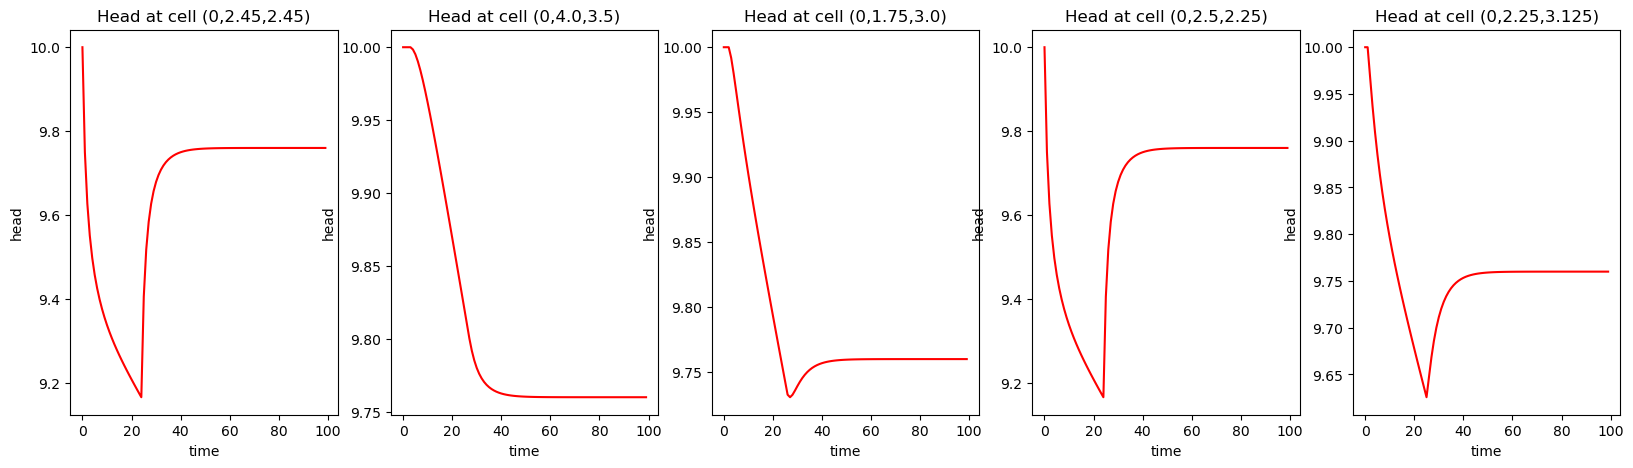

In [420]:
Lx, Ly = 1000, 1000
obsWell = [[0, 490, 490], [0, 800, 700], [0, 350, 600], [0,500, 450], [0, 450, 625]]

fig = plt.figure(figsize=(20,5))
for ii in range(5):
    col_i = int(obsWell[ii][1] * model.n_col / Lx)
    row_i = int(obsWell[ii][2] * model.n_row / Ly)

    ax = fig.add_subplot(1, 5, ii+1)
    ttl = f"Head at cell ({0},{obsWell[ii][1]/200},{obsWell[ii][2]/200})"
    ax.set_title(ttl)
    ax.set_xlabel("time")
    ax.set_ylabel("head")
    ax.plot(heads[col_i + model.n_col*row_i,:], "r-")
    #ax.set_ylim([8.7, 10])

No oscillations

### Check aggregated matrices

In [421]:
# Initialize Controller
controller = LTI_LQRc_RHG(
    parameter_file,
    model.A.toarray(), [B.toarray() for B in model.B_v], [B.toarray() for B in model.B_minus_v], model.C,
    model.H_x, model.h_x, model.H_u, model.h_u,
    Q_v = None, R_v = None, M_v = [G.toarray() for G in model.Gamma_v], L_v = [Xi for Xi in model.Xi_v]
)

In [422]:
assert (controller.A_tilde[:25, :] == np.eye(25)).all()
assert (controller.A_tilde[25:50, :] == model.A).all()
assert not (controller.A_tilde[50:75, :] - model.A @ model.A).round(5).any()
assert not (controller.A_tilde[75:100, :] - model.A @ model.A @ model.A).round(5).any()

In [423]:
Knu = controller.B_tilde.shape[1]
assert (controller.B_tilde[:25, :] == np.zeros((25,Knu))).all()
assert (controller.B_tilde[25:50, :4] == B).all()
assert (controller.B_tilde[25:50, 4:] == np.zeros((25,Knu-4))).all()
assert (controller.B_tilde[50:75, :4] == model.A @ B).all()
assert (controller.B_tilde[50:75, 4:8] == B).all()
assert (controller.B_tilde[50:75, 8:] == np.zeros((25,Knu-8))).all()
assert not (controller.B_tilde[75:100, :4] - model.A @ model.A @ B).round(10).any()
assert (controller.B_tilde[75:100, 4:8] == model.A @ B).all()
assert (controller.B_tilde[75:100, 8:12] == B).all()

In [424]:
U = np.vstack((np.kron(np.ones((5,1)), q_1), np.kron(np.ones((5,1)), q_2)))
X = controller.A_tilde @ h_0 + controller.B_tilde @ U + controller.C_tilde

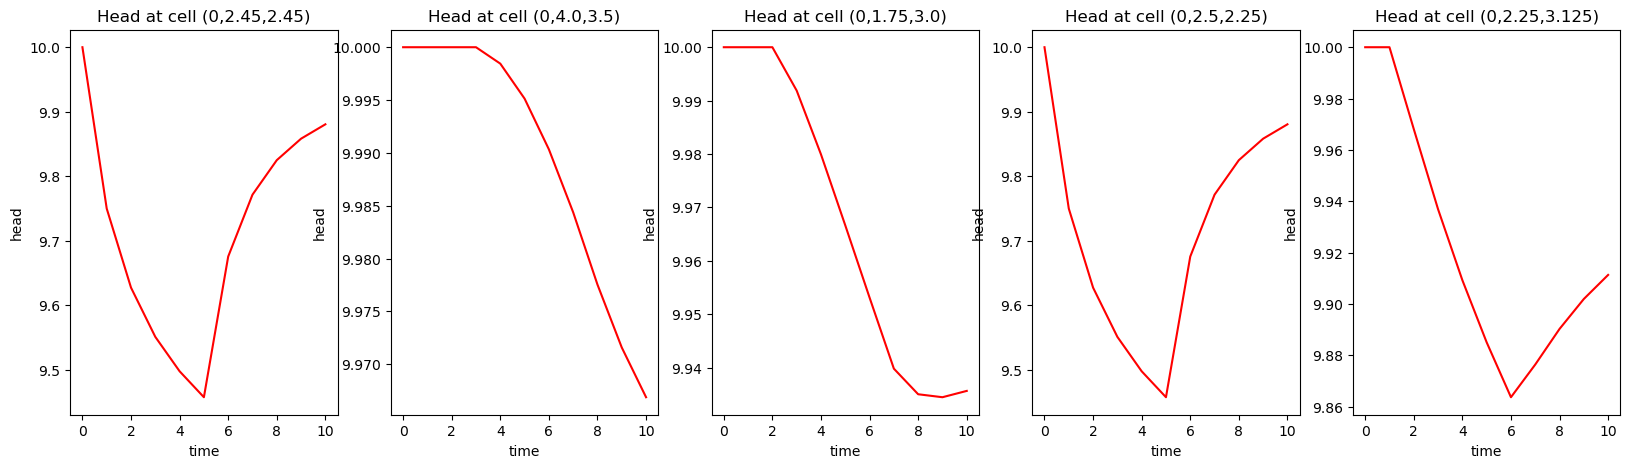

In [425]:
heads = X.reshape(11,25).T
fig = plt.figure(figsize=(20,5))
for ii in range(5):
    col_i = int(obsWell[ii][1] * model.n_col / Lx)
    row_i = int(obsWell[ii][2] * model.n_row / Ly)

    ax = fig.add_subplot(1, 5, ii+1)
    ttl = f"Head at cell ({0},{obsWell[ii][1]/200},{obsWell[ii][2]/200})"
    ax.set_title(ttl)
    ax.set_xlabel("time")
    ax.set_ylabel("head")
    ax.plot(heads[col_i + model.n_col*row_i,:], "r-")
    #ax.set_ylim([8.7, 10])

### Check constraints

In [426]:
controller.H_u.toarray() , controller.h_u.toarray().T

(array([[ 1.,  0.,  0.,  0.],
        [ 0.,  1.,  0.,  0.],
        [ 0.,  0.,  1.,  0.],
        [ 0.,  0.,  0.,  1.],
        [-1.,  0.,  0.,  0.],
        [ 0., -1.,  0.,  0.],
        [ 0.,  0., -1.,  0.],
        [ 0.,  0.,  0., -1.]]),
 array([[   0.,    0.,    0.,    0., 2000., 1000., 1000., 1000.]]))

In [427]:
(controller.H_u.toarray() @ np.array([[-1000,-1000,-3,-4]]).T <= controller.h_u.toarray()).T

array([[ True,  True,  True,  True,  True,  True,  True,  True]])

In [428]:
controller.H_x.data, controller.h_x.toarray().T

(array([[-1., -1., -1., -1., -1., -1., -1., -1., -1., -1., -1., -1., -1.,
         -1., -1., -1., -1., -1., -1., -1., -1., -1., -1., -1., -1.]]),
 array([[40. , 40. , 40. , 40. , 40. , 40. , 40. , 40. , 35. , 40. , 40. ,
         40. , -8.5, 40. , 40. , 40. , 40. , 40. , 40. , 40. , 40. , 40. ,
         40. , 30. , 40. ]]))

In [429]:
H, h = controller._compute_constraints(h_0)
H, h

(<COOrdinate sparse matrix of dtype 'float64'
 	with 3137 stored elements and shape (355, 40)>,
 <COOrdinate sparse array of dtype 'float64'
 	with 355 stored elements and shape (355, 1)>)

In [456]:
(H @ np.kron(np.ones((10,1)), q_1) <= h).all()

np.True_

### Check cost

In [462]:
model.Xi_v

[array([[19.]]), array([[35., 35.]]), array([[17.]])]

In [473]:
[h_0.T @ model.Gamma_v[i] for i in range(3)]

[array([[-40.]]), array([[-40., -40.]]), array([[-20.]])]

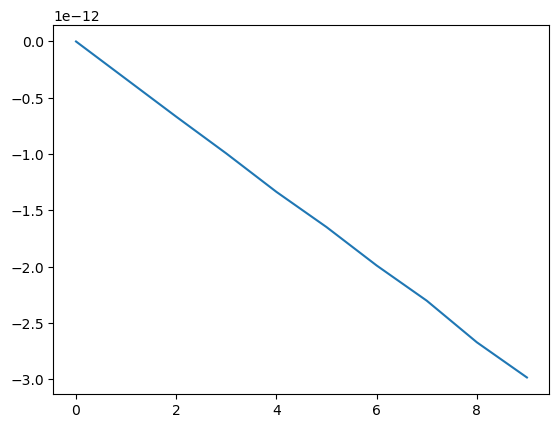

In [ ]:
u = np.linspace(0,10,10)
plt.plot((h_0.T @ model.Gamma_v[0] * u + model.Xi_v[0] * u).flatten())

Given an initial head, it is a linear function in u

Let't plot the gradient as a function of h_0

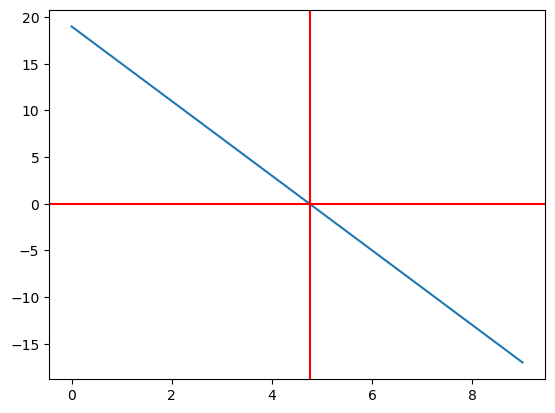

In [543]:
plt.plot([(x*np.ones((25,1)).T @ model.Gamma_v[0] + model.Xi_v[0]).flatten() for x in range(10)])
plt.axhline(0, c='r')
plt.axvline(4.75, c='r')

In [548]:
model.Gamma_v[0].toarray().T

array([[ 0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0., -4.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.]])

In [ ]:
print([(Q_v == 0).all() for Q_v in controller.tilde_Q_v])
print([not (R_v != 0).toarray().any() for R_v in controller.tilde_R_minus_v_minus_v])
print([not (M_v != 0).any() for M_v in controller.tilde_M_x_u_minus_v])

[np.True_, np.True_, np.True_]
[True, True, True]
[True, True, True]


In [574]:
controller.B_v_tilde[0].shape

/Users/leonardchanfreau/miniconda3/envs/modflowenv/lib/python3.13/site-packages/executing/executing.py:713: DeprecationWarning: ast.Str is deprecated and will be removed in Python 3.14; use ast.Constant instead
  right=ast.Str(s=sentinel),
/Users/leonardchanfreau/miniconda3/envs/modflowenv/lib/python3.13/ast.py:608: DeprecationWarning: Constant.__init__ got an unexpected keyword argument 's'. Support for arbitrary keyword arguments is deprecated and will be removed in Python 3.15.
  return Constant(*args, **kwargs)
/Users/leonardchanfreau/miniconda3/envs/modflowenv/lib/python3.13/ast.py:608: DeprecationWarning: Attribute s is deprecated and will be removed in Python 3.14; use value instead
  return Constant(*args, **kwargs)
/Users/leonardchanfreau/miniconda3/envs/modflowenv/lib/python3.13/ast.py:608: DeprecationWarning: Constant.__init__ missing 1 required positional argument: 'value'. This will become an error in Python 3.15.
  return Constant(*args, **kwargs)
/Users/leonardchanfreau/

AttributeError: 'LTI_LQRc_RHG' object has no attribute 'B_v_tilde'

In [571]:
controller.tilde_R_v_v[0].toarray()

array([[ 0.        , -0.002     , -0.00098   , -0.00061025, -0.00042647,
        -0.00032167, -0.00025638, -0.00021289, -0.00018242, -0.00016024],
       [ 0.        ,  0.        , -0.002     , -0.00098   , -0.00061025,
        -0.00042647, -0.00032167, -0.00025638, -0.00021289, -0.00018242],
       [ 0.        ,  0.        ,  0.        , -0.002     , -0.00098   ,
        -0.00061025, -0.00042647, -0.00032167, -0.00025638, -0.00021289],
       [ 0.        ,  0.        ,  0.        ,  0.        , -0.002     ,
        -0.00098   , -0.00061025, -0.00042647, -0.00032167, -0.00025638],
       [ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        -0.002     , -0.00098   , -0.00061025, -0.00042647, -0.00032167],
       [ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        , -0.002     , -0.00098   , -0.00061025, -0.00042647],
       [ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        , -0.002     

In [457]:
# Initialize receding horizon
receding_horizon = RecedingHorizon(system, model, controller)
# Run loop
receding_horizon.run(time_period=52)

/Users/leonardchanfreau/miniconda3/envs/modflowenv/lib/python3.13/site-packages/executing/executing.py:713: DeprecationWarning: ast.Str is deprecated and will be removed in Python 3.14; use ast.Constant instead
  right=ast.Str(s=sentinel),
/Users/leonardchanfreau/miniconda3/envs/modflowenv/lib/python3.13/ast.py:608: DeprecationWarning: Constant.__init__ got an unexpected keyword argument 's'. Support for arbitrary keyword arguments is deprecated and will be removed in Python 3.15.
  return Constant(*args, **kwargs)
/Users/leonardchanfreau/miniconda3/envs/modflowenv/lib/python3.13/ast.py:608: DeprecationWarning: Attribute s is deprecated and will be removed in Python 3.14; use value instead
  return Constant(*args, **kwargs)
/Users/leonardchanfreau/miniconda3/envs/modflowenv/lib/python3.13/ast.py:608: DeprecationWarning: Constant.__init__ missing 1 required positional argument: 'value'. This will become an error in Python 3.15.
  return Constant(*args, **kwargs)
/Users/leonardchanfreau/

RuntimeError: MODFLOW did not terminate normally.